## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Santiago Camacho" # @param {"type":"string"}
carnet = 1011101295 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**


Una tienda requiere optimizar el proceso de consulta, almacenamiento y gestion de los productos pertenecientes a su inventario. En la actualidad, el registro masivo de articulos provoca que recorrer secuencialmente una lista completa para localizar un elemento sea una operacion ineficiente y lenta.

Para resolver esta problematica, se implementa un sistema fundamentado en una tabla hash manual, utilizando como llave primaria el codigo numerico del producto. Cada registro almacena codigo, nombre, precio y cantidad disponible. La solucion contempla la inicializacion de la tabla a partir de un tamaño m parametrizado por el usuario, la asignacion de posiciones mediante la funcion hash $h(\text{código}) = \text{código} \pmod m$, la resolucion de colisiones mediante encadenamiento y las operaciones de insercion, busqueda, eliminacion, actualizacion de inventario y visualizacion grafica del estado interno de la estructura

## 2) Requerimientos **[2 pts]**

Requerimientos Funcionales
- El sistema debe solicitar el tamaño m al usuario e inicializar la estructura indexada de 0 a m-1 en estado vacio
- Permitir el registro de n productos solicitando codigo, nombre, precio y cantidad. Se debe calcular mediante la funcion hash y validar que el codigo no exista previamente.
- Si dos o mas llaves generan el mismo indice hash, el sistema debe encadenar los elementos dentro de una lista enlazada en la celda correspondiente
- Dado un codigo, el sistema aplicara la funcion hash para ubicarse directamente en la posicion de la tabla y buscar el producto en su lista encadenada sin realizar un recorrido total de la estructura
-Permitir remover un elemento mediante su codigo indentificador, localizandolo por la funcion hash y desvinculando su nodo dentro de la lista encadenada respectiva
- Localizar un producto por su codigo

Requerimientos No Funcionales
- La estructura de la tabla hash y el encadenamiento deben programarse manualmente sin acudir a colecciones hash automaticas del lenguaje
- El programa se interactuara a travez de una interfaz por linea de comandos limpios
-Garantizar un acceso indexado de complejidad O(1) en promedio para busquedas y operaciones derivadas


## 3) Historias de usuario **[2 pts]**



Historia de usuario 1
- Como administrador de la tienda , quiero definir el tamaño m de la tabla hash al incio del programa, para dimensionar la estructura segun la cantidad estimada de productos
     - Criterios de aceptacion
         - el sistema solicita al usuario ingresar el tamaño m
         - Inicializa m celdas de la lista con un valor nulo/vacio

Historia de usuario 2
- Como encargado de inventario, quiero ingresar la informacion de los nuevos articulos, para agregarlos al sistema calculando su posicion automatica
    - Criterios de aceptacion
        - El sistema posiciona el elemento ejecutando $h(\text{código}) = \text{código} \pmod m$.
        - Si ocurre colision, agrega el nuevo nodo al encadenamiento existente
        - Rechaza la insercion si el codigo ingresado ya esta registrado
    
Historia de usuario 3
- Como empleado del negocio, quiero consultar un producto a traves de su codigo, para revisar su informacion y stock en tiempo real
   - Criterios de aceptacion
      - Aplica la funcion hash e inspecciona unicamente la celda correspondiente
      - Retorna los datos detallados de producto o notifica que no existe

Historia de usuario 4
- Como administrador de inventario, quiero modificar las unidades en existencia de un producto por su codigo, para mantener al dia las novedades de mercancia
   - Criterios de aceptacion
      - Accede por hash al producto objetivo
      - Sustituye la cantidad anterior por la nueva cifra ingresada

## 4) Diagramas de flujo **[5 pts]**



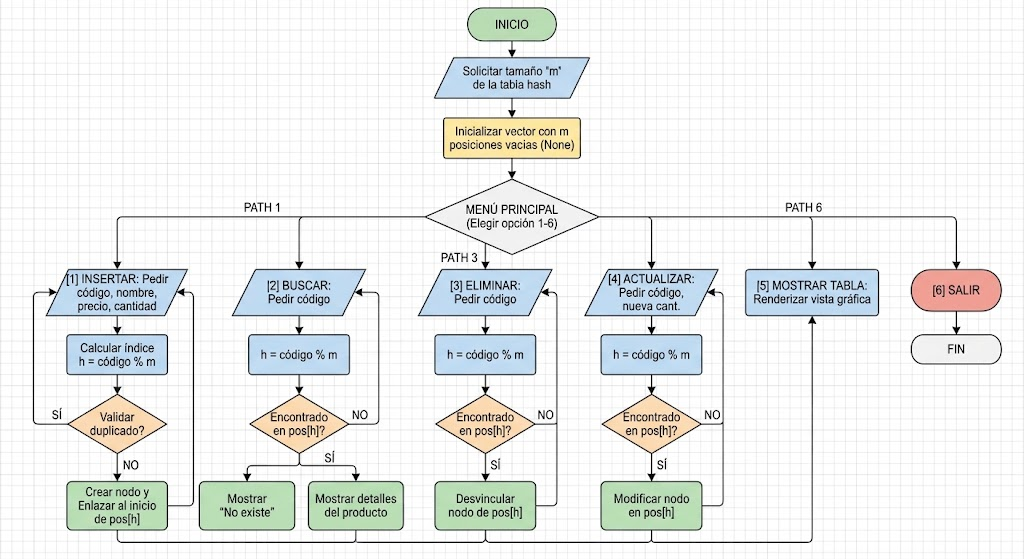

El sistema inicia solicitando el tamaño $m$ para crear la tabla hash vacía. A continuación, presenta un menú interactivo con las opciones de insertar, buscar, eliminar, actualizar, mostrar y salir. Para las operaciones de gestión, se calcula automáticamente el índice mediante la función hash $h(\text{código}) = \text{código} \pmod m$, accediendo de forma directa a la celda para manipular el elemento o recorrer su lista encadenada en caso de colisión.

## 5) Diagramas de secuencia **[5 pts]**


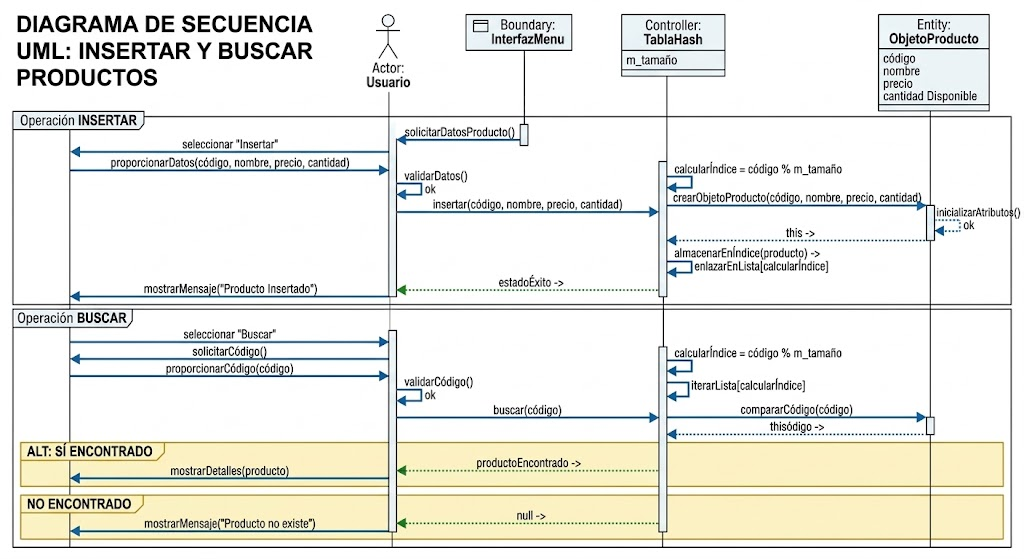

El diagrama de secuencia ilustra los procesos de inserción y búsqueda de productos a través de cuatro participantes: el usuario, la interfaz, el controlador de la tabla hash y el objeto producto. En la inserción, el sistema recibe los datos ingresados, calcula el índice mediante la función hash, crea el nodo correspondiente y lo encadena en la posición debida. En la búsqueda, el controlador localiza el índice por hash, recorre la lista enlazada y muestra los detalles del artículo si existe o un mensaje de error si no se encuentra.

## 6) Diagramas de casos de uso **[5 pts]**


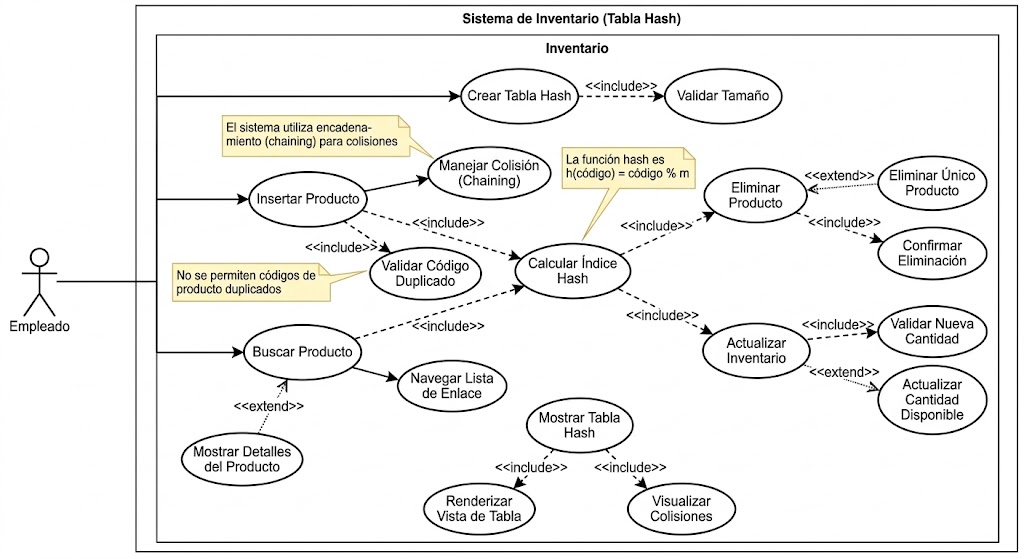

El diagrama de casos de uso muestra la interacción del Empleado con el sistema para gestionar el inventario mediante una tabla hash. Incluye las operaciones principales —crear tabla, insertar, buscar, eliminar, actualizar y mostrar— apoyadas por relaciones de inclusión y extensión que detallan el cálculo del índice hash, la validación de duplicados y el manejo de colisiones por encadenamiento.

## 7) Análisis de complejidad **[5 pts]**



- Justificación: Garantiza un acceso directo mediante la función hash en tiempo $O(1)$ en promedio, viéndose afectado únicamente por el recorrido de la lista encadenada en caso de colisiones

- Función T[n]: $T(n) = c_1 + c_2 \cdot k$

- Mejor y peor caso con gráfica

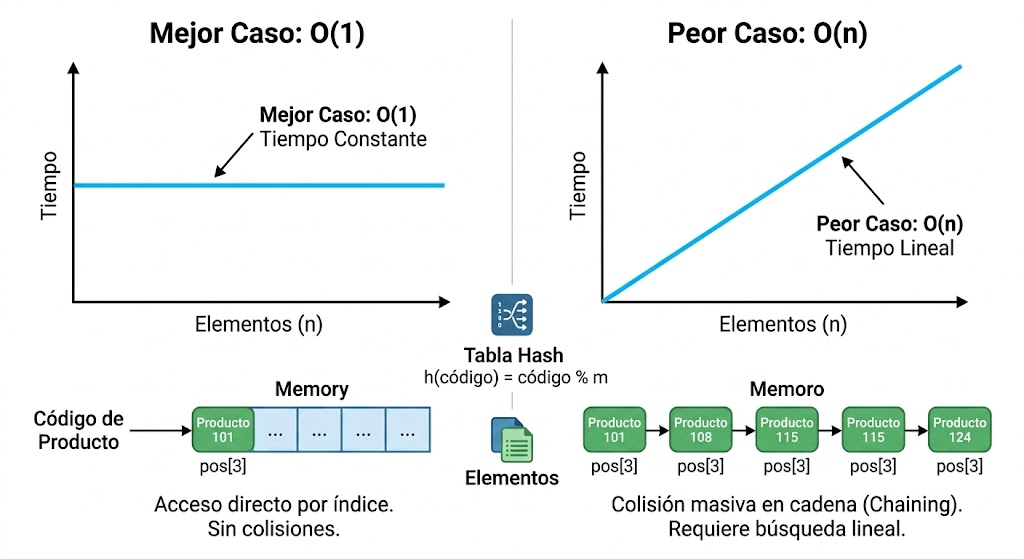

## 8) Código funcional **[10 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [8]:
class Producto:
    def __init__(self, codigo, nombre, precio, cantidad):
        self.codigo = codigo
        self.nombre = nombre
        self.precio = precio
        self.cantidad = cantidad
        self.siguiente = None


class InventarioHash:
    def __init__(self, tamano_m):
        self.tamano_m = tamano_m
        self.casillas = [None] * tamano_m

    def calcular_posicion(self, codigo):
        return codigo % self.tamano_m

    def registrar_producto(self, codigo, nombre, precio, cantidad):
        posicion = self.calcular_posicion(codigo)

        producto_actual = self.casillas[posicion]
        while producto_actual is not None:
            if producto_actual.codigo == codigo:
                print(f"Error: El producto con código {codigo} ya existe.")
                return
            producto_actual = producto_actual.siguiente

        nuevo_producto = Producto(codigo, nombre, precio, cantidad)
        nuevo_producto.siguiente = self.casillas[posicion]
        self.casillas[posicion] = nuevo_producto
        print(f"Producto '{nombre}' guardado exitosamente en la posición {posicion}.")

    def consultar_producto(self, codigo):
        posicion = self.calcular_posicion(codigo)
        producto_actual = self.casillas[posicion]

        while producto_actual is not None:
            if producto_actual.codigo == codigo:
                return producto_actual
            producto_actual = producto_actual.siguiente
        return None

    def eliminar_producto(self, codigo):
        posicion = self.calcular_posicion(codigo)
        producto_actual = self.casillas[posicion]
        producto_anterior = None

        while producto_actual is not None:
            if producto_actual.codigo == codigo:
                if producto_anterior is None:
                    self.casillas[posicion] = producto_actual.siguiente
                else:
                    producto_anterior.siguiente = producto_actual.siguiente
                print(f"Producto con código {codigo} eliminado correctamente.")
                return
            producto_anterior = producto_actual
            producto_actual = producto_actual.siguiente

        print("No se encontró el producto.")

    def cambiar_cantidad_disponible(self, codigo, nueva_cantidad):
        producto_encontrado = self.consultar_producto(codigo)
        if producto_encontrado is not None:
            producto_encontrado.cantidad = nueva_cantidad
            print(f"Inventario actualizado: {producto_encontrado.nombre} ahora tiene {nueva_cantidad} unidades.")
        else:
            print("No se encontró el producto para actualizar.")

    def ver_inventario_completo(self):
        print("\n--- ESTADO DE LA TABLA HASH ---")
        for indice in range(self.tamano_m):
            producto_actual = self.casillas[indice]
            texto_fila = f"Posición {indice}: "

            if producto_actual is None:
                texto_fila += "Vacío"
            else:
                while producto_actual is not None:
                    texto_fila += f"[{producto_actual.codigo} - {producto_actual.nombre}] -> "
                    producto_actual = producto_actual.siguiente
                texto_fila += "Fin"

            print(texto_fila)


if __name__ == "__main__":
    tamano = int(input("Ingrese el tamaño m de la tabla hash: "))
    tienda = InventarioHash(tamano)

    while True:
        print("\n=== MENÚ DE INVENTARIO ===")
        print("1. Insertar producto")
        print("2. Buscar producto")
        print("3. Eliminar producto")
        print("4. Actualizar cantidad de producto")
        print("5. Mostrar tabla hash")
        print("6. Salir")

        opcion = input("Elija una opción (1-6): ")

        if opcion == "1":
            cod = int(input("Código numérico: "))
            nom = input("Nombre del producto: ")
            pre = float(input("Precio: "))
            cant = int(input("Cantidad inicial: "))
            tienda.registrar_producto(cod, nom, pre, cant)

        elif opcion == "2":
            cod = int(input("Código a buscar: "))
            prod = tienda.consultar_producto(cod)
            if prod:
                print(f"-> Encontrado: {prod.nombre} | Precio: ${prod.precio} | Cantidad: {prod.cantidad}")
            else:
                print("El producto no está registrado.")

        elif opcion == "3":
            cod = int(input("Código a eliminar: "))
            tienda.eliminar_producto(cod)

        elif opcion == "4":
            cod = int(input("Código a actualizar: "))
            nueva_cant = int(input("Nueva cantidad disponible: "))
            tienda.cambiar_cantidad_disponible(cod, nueva_cant)

        elif opcion == "5":
            tienda.ver_inventario_completo()

        elif opcion == "6":
            print("Programa finalizado.")
            break
        else:
            print("Opción no válida. Intente de nuevo.")



=== MENÚ DE INVENTARIO ===
1. Insertar producto
2. Buscar producto
3. Eliminar producto
4. Actualizar cantidad de producto
5. Mostrar tabla hash
6. Salir
Producto 'Carro' guardado exitosamente en la posición 2.

=== MENÚ DE INVENTARIO ===
1. Insertar producto
2. Buscar producto
3. Eliminar producto
4. Actualizar cantidad de producto
5. Mostrar tabla hash
6. Salir
Producto 'Moto' guardado exitosamente en la posición 3.

=== MENÚ DE INVENTARIO ===
1. Insertar producto
2. Buscar producto
3. Eliminar producto
4. Actualizar cantidad de producto
5. Mostrar tabla hash
6. Salir
Producto 'Lancha' guardado exitosamente en la posición 2.

=== MENÚ DE INVENTARIO ===
1. Insertar producto
2. Buscar producto
3. Eliminar producto
4. Actualizar cantidad de producto
5. Mostrar tabla hash
6. Salir
Producto 'BMW' guardado exitosamente en la posición 1.

=== MENÚ DE INVENTARIO ===
1. Insertar producto
2. Buscar producto
3. Eliminar producto
4. Actualizar cantidad de producto
5. Mostrar tabla hash
6. Salir

## 9) pruebas **[15 pts]**

In [16]:

tienda = InventarioHash(4)
datos_prueba = [
    (1234, "Carro", 12000.0, 6000),
    (987, "Moto", 15000.0, 3000),
    (7654, "Lancha", 50000.0, 500),
    (1209, "BMW", 100000.0, 100)
]

for codigo, nombre, precio, cantidad in datos_prueba:
    tienda.registrar_producto(codigo, nombre, precio, cantidad)

for codigo, nombre, precio, cantidad in datos_prueba:
    prod = tienda.consultar_producto(codigo)
    assert prod is not None, f"El producto {nombre} con código {codigo} debería existir"
    assert prod.nombre == nombre, f"El nombre almacenado debe coincidir con {nombre}"

    pos_esperada = codigo % tienda.tamano_m
    assert tienda.calcular_posicion(codigo) == pos_esperada


codigo_prueba = datos_prueba[0][0]
nueva_cantidad = 15000
tienda.cambiar_cantidad_disponible(codigo_prueba, nueva_cantidad)
assert tienda.consultar_producto(codigo_prueba).cantidad == nueva_cantidad

tienda.eliminar_producto(codigo_prueba)
assert tienda.consultar_producto(codigo_prueba) is None, "El producto eliminado ya no debe encontrarse"

print("¡Pruebas dinámicas ejecutadas y verificadas correctamente con el código!")

Producto 'Carro' guardado exitosamente en la posición 2.
Producto 'Moto' guardado exitosamente en la posición 3.
Producto 'Lancha' guardado exitosamente en la posición 2.
Producto 'BMW' guardado exitosamente en la posición 1.
Inventario actualizado: Carro ahora tiene 15000 unidades.
Producto con código 1234 eliminado correctamente.
¡Pruebas dinámicas ejecutadas y verificadas correctamente con el código!
